## 梯度下降法-一元线性回归
最终拟合出的函数形如
> $$
\hat{y}=wx+b
$$
均方误差为
> $$
L\left(w,b\right)=\frac{1}{N}\sum_{i=1}^{N}\left(\hat{y}_{i}-y_{i}\right)^2
$$
其中，$L\left(w,b\right)$为损失函数，$\hat{y}_{i}=\hat{y}_{i}\left(w,b\right)=wx_{i}+b$为第$i$个样本的估计值，$y_{i}$为第$i$个样本的实际值

---
现在推导权重,截距的表达式，损失函数对权重,截距求偏导，得
$$
\begin{align*} & \frac{\partial}{\partial w}L\left(w,b\right)=\frac{2}{N}\sum_{i=1}^{N}\left(\hat{y}_{i}-y_{i}\right)\frac{\partial\hat{y}_{i}}{\partial w}=\frac{2}{N}\sum_{i=1}^{N}\left(\hat{y}_{i}-y_{i}\right)x_{i}\\  & \frac{\partial}{\partial b}L\left(w,b\right)=\frac{2}{N}\sum_{i=1}^{N}\left(\hat{y}_{i}-y_{i}\right)\frac{\partial\hat{y}_{i}}{\partial b}=\frac{2}{N}\sum_{i=1}^{N}\left(\hat{y}_{i}-y_{i}\right)\end{align*}
$$
权重,截距迭代公式为
> $$
\begin{align*} & w^{\left(k+1\right)}=w^{\left(k\right)}-\eta\frac{\partial}{\partial w^{\left(k\right)}}L\left(w^{\left(k\right)},b^{\left(k\right)}\right)\\  & b^{\left(k+1\right)}=b^{\left(k\right)}-\eta\frac{\partial}{\partial b^{\left(k\right)}}L\left(w^{\left(k\right)},b^{\left(k\right)}\right)\end{align*}
$$
其中，$\eta$为学习率

---
取函数表达式为：
$$
y=3x+4
$$
数据集采用$y=3x+4+noise$，其中$noise$为噪声，使数据集更贴合真实情况

In [1]:
# 导入库
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 创建随机数据集
random_seed = 31    # 指定随机种子，便于复现
rng = np.random.default_rng(random_seed)    # 创建随机种子生成器rng，后续的随机数据都基于rng生成

number_data = 150    # 数据总数
X = np.random.uniform(-5, 5, number_data)     # 从[-5, 5]上随机生成150个数
noise = np.random.normal(0, 1, number_data)    # 按照均值为0,标准差为0.5的正态分布，随机地生成150个数

y = 3 * X + 4 + noise    # 指定的线性关系式，必须考虑上噪声

# 打印部分数据
print(f"X的前5个：{X[:5]}")
print(f"y的前5个：{y[:5]}")

X的前5个：[ 3.71335717 -3.00307761  4.95146698 -1.02993323  1.13157543]
y的前5个：[14.45359088 -5.36684139 19.5075933  -0.37828747  6.62515919]


In [3]:
# 划分训练集,测试集
rng1 = np.random.default_rng(random_seed+1)    # 更换随机种子，当然这不是必需的
random_numbers = rng1.permutation(number_data)     # 将序列[0,1,2...,148,149]随机打乱，这也不是必需的，因为(X,Y)已经是乱序的

test_size = 0.2    # 测试集占比
bound = int(number_data * (1-test_size))    # 分割训练集与测试集的点，直接算出来是浮点型数据120.0，应转换成整数型120

X_train = X[random_numbers[:bound]]    # 0,1,2,...,118,119
X_test = X[random_numbers[bound:]]    # 120,121,...,148,149
y_train = y[random_numbers[:bound]]    # 0,1,2,...,118,119
y_test = y[random_numbers[bound:]]    # 120,121,...,148,149

# 打印部分数据
print(f"打乱的序列为（前10个）：{random_numbers[:10]}")
print(f"分界点：{bound}")
print(f"X_train,y_train的个数：{len(X_train)}")
print(f"X_test,y_test的个数：{len(X_test)}")
print(f"X_train的前5个：{X_train[:5]}")
print(f"y_train的前5个：{y_train[:5]}")

打乱的序列为（前10个）：[37 82 76 59 77 26  0 49 85 98]
分界点：120
X_train,y_train的个数：120
X_test,y_test的个数：30
X_train的前5个：[ 4.60119429 -3.02471884  0.31880335 -1.96804345 -0.88651756]
y_train的前5个：[18.17825288 -4.39663126  5.89189816 -3.52547251  1.32556879]


In [4]:
# 初始化模型参数
learn_rate = 0.05    # 学习率
w = 0    # 权重
b = 0    # 截距
max_delta = 1e-8    # max(|权重|,|截距|)相邻变化的临界值，低于此值即满足训练要求
upper_time = 2000    # 训练次数上限
loss_history = []    # 记录损失函数的变化，用于绘制变化图像
w_history = [w]    # 记录权重的变化，用于求出变化量
b_history = [b]    # 记录截距的变化，用于求出变化量
flag = 1    # 训练次数的记号

In [5]:
# 训练模型
while True:
    y_cap = w * X_train + b    # 估计值

    loss = np.mean((y_cap - y_train) ** 2)    # 损失函数
    loss_history.append(loss)    # 记录损失函数

    L_w = 2 * np.mean((y_cap - y_train) * X_train)    # 损失函数对权重w的偏导数
    L_b = 2 * np.mean(y_cap - y_train)    # 损失函数对截距b的偏导数
    w -= learn_rate * L_w    # 迭代下一次的权重w
    b -= learn_rate * L_b    # 迭代下一次的截距b
    w_history.append(w)    # 记录权重
    b_history.append(b)    # 记录截距

    # 权重,截距的变化
    delta_w = w_history[flag] - w_history[flag-1]    # 权重的变化量
    delta_b = b_history[flag] - b_history[flag-1]    # 截距的变化量
    delta = np.abs([delta_w, delta_b])    # 只考虑其数值

    # 每10次打印一次结果
    if flag % 10 == 0:
        print(f"第{flag}次训练：权重w={w}，截距b={b}")

    # 结束训练条件之一：差值满足要求
    if np.max(delta) < max_delta:
        print(f"已达要求，训练次数：{flag}")
        break

    # 结束训练条件之二：次数达到上限
    if flag == upper_time:
        print(f"训练次数达到{upper_time}，已结束训练！")
        break

    flag += 1    # 训练次数加一

print(f"权重：w={w:.2f}，截距：{b:.2f}\n最终方程：y={w:.2f}x+{b:.2f}")    # 展示结果
    

第10次训练：权重w=2.9553736450455923，截距b=2.620218832851637
第20次训练：权重w=2.9427642554732993，截距b=3.5208027566320204
第30次训练：权重w=2.938359933533043，截距b=3.8353668713271905
第40次训练：权重w=2.9368215520503282，截距b=3.9452406761347625
第50次训练：权重w=2.936284212224026，截距b=3.9836183944405876
第60次训练：权重w=2.9360965252996998，截距b=3.9970233116994445
第70次训练：权重w=2.936030968309805，截距b=4.001705502685497
第80次训练：权重w=2.9360080699702458，截距b=4.003340940786795
第90次训练：权重w=2.936000071830682，截距b=4.003912181428438
第100次训练：权重w=2.935997278168009，截距b=4.004111709536783
第110次训练：权重w=2.935996302372193，截距b=4.004181402522747
第120次训练：权重w=2.9359959615373863，截距b=4.004205745520495
第130次训练：权重w=2.9359958424875163，截距b=4.004214248263365
第140次训练：权重w=2.9359958009046987，截距b=4.004217218178453
第150次训练：权重w=2.9359957863802757，截距b=4.004218255537309
第160次训练：权重w=2.9359957813070534，截距b=4.004218617875413
已达要求，训练次数：168
权重：w=2.94，截距：4.00
最终方程：y=2.94x+4.00


In [6]:
# 测试模型
y_pred = w * X_test + b

# 计算均方误差
test_mes = np.mean((y_pred - y_test) ** 2)
print(f"测试集的均方误差为：MES={test_mes}")

测试集的均方误差为：MES=1.632167689923205


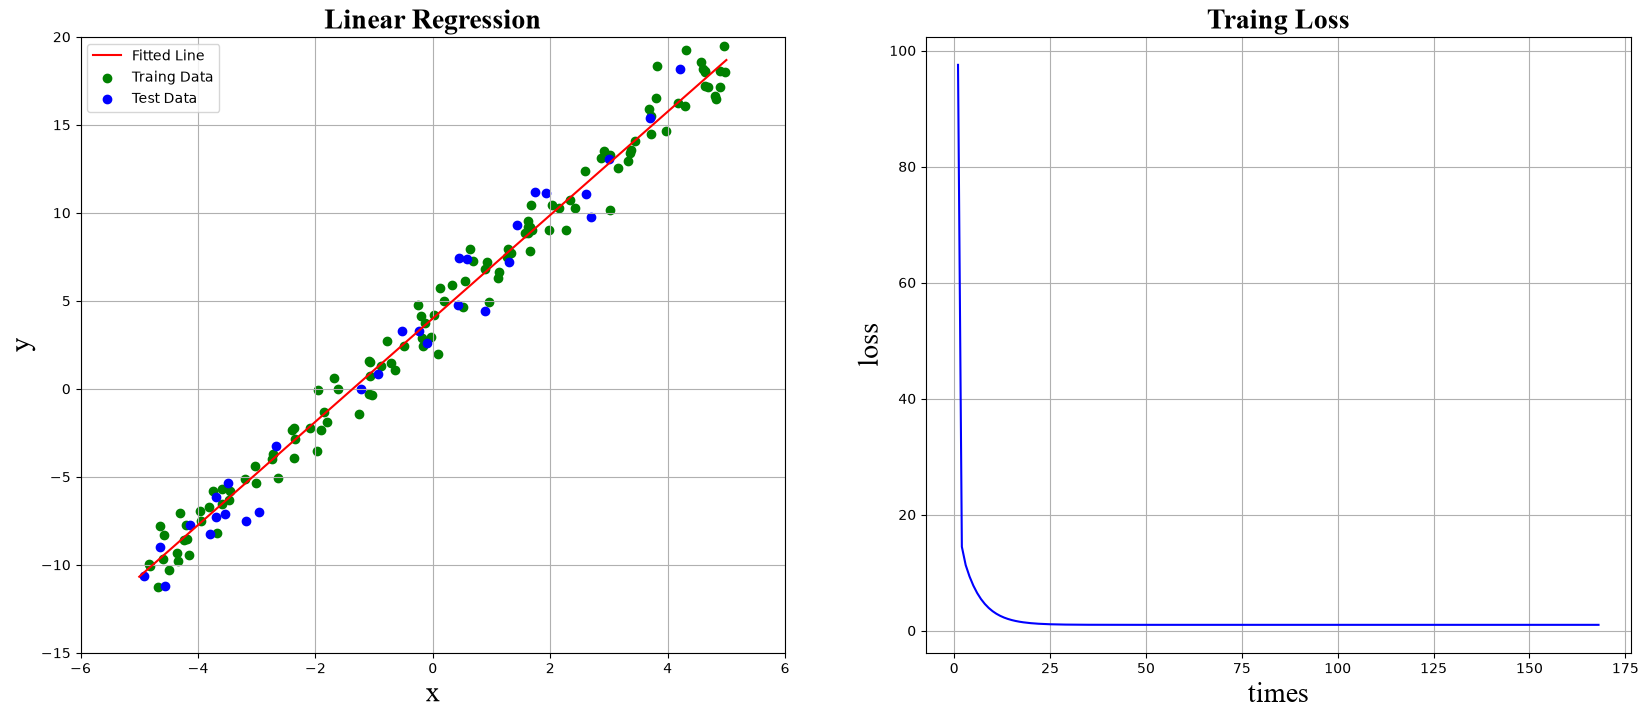

In [7]:
# 可视化
fig, axs = plt.subplots(    # 创建画布和坐标轴（2个坐标轴）
    1, 2,    # 1*2的子图
    figsize=(20, 8),    # 尺寸
    dpi=100    # 分辨率
)

X_line = np.linspace(-5, 5, number_data)    # 拟合曲线的横轴变量
Y_hat = w * X_line + b    # 拟合曲线的纵轴变量

loss_history = np.array(loss_history, dtype=float)    # 原数据类型为np.float()，不可与x_loss直接绘图，需转换成普通float型
x_loss = np.arange(1, len(loss_history)+1)    # 损失函数变化的横轴变量

# 编辑图[0]
axs[0].plot(    # 绘制拟合曲线
    X_line,    # 横轴变量
    Y_hat,    # 纵轴变量
    label="Fitted Line",    # 图例
    color="r"    # 颜色
)
axs[0].scatter(    # 绘制训练集的散点图
    X_train,    # 横轴变量
    y_train,    # 纵轴变量
    label="Traing Data",    # 图例
    color="g"    # 颜色
)
axs[0].scatter(    # 绘制测试集的散点图
    X_test,    # 横轴变量
    y_test,    # 纵轴变量
    label="Test Data",    # 图例
    color="b"    # 颜色
)

axs[0].set_xlabel(    # 设置横轴标题
    "x",    # 名称
    fontfamily="Times New Roman",    # 字体
    fontsize=20,    # 字号
)
axs[0].set_ylabel(    # 设置纵轴标题
    "y",    # 名称
    fontfamily="Times New Roman",    # 字体
    fontsize=20,    # 字号
)
axs[0].set_title(    # 设置标题
    "Linear Regression",    # 名称
    fontfamily="Times New Roman",    # 字体
    fontsize=20,    # 字号
    fontweight="bold"    # 粗体
)

axs[0].set_xlim(-6, 6)    # 横轴范围
axs[0].set_ylim(-15, 20)    # 纵轴范围

axs[0].legend()    # 显示图例
axs[0].grid(True)    # 显示网格

# 编辑图[1]
axs[1].plot(    # 绘制拟合曲线
    x_loss,    # 横轴变量
    loss_history,    # 纵轴变量
    color="b"    # 颜色
)

axs[1].set_xlabel(    # 设置横轴标题
    "times",    # 名称
    fontfamily="Times New Roman",    # 字体
    fontsize=20,    # 字号
)
axs[1].set_ylabel(    # 设置纵轴标题
    "loss",    # 名称
    fontfamily="Times New Roman",    # 字体
    fontsize=20,    # 字号
)

axs[0].set_xlabel(    # 设置横轴标题
    "x",    # 名称
    fontfamily="Times New Roman",    # 字体
    fontsize=20,    # 字号
)
axs[1].set_title(    # 设置标题
    "Traing Loss",    # 名称
    fontfamily="Times New Roman",    # 字体
    fontsize=20,    # 字号
    fontweight="bold"    # 粗体
)

axs[1].grid(True)    # 显示网格

plt.show()    # 展示图像